# Лабораторна робота №5 — Основи штучного інтелекту
## Завдання 2. Згорткова нейронна мережа (CNN) для класифікації рукописних цифр

**Мета:** дослідити використання згорткової нейронної мережі (CNN) з бібліотекою Keras для класифікації зображень **MNIST (28×28, класи 0–9)**, перевірити модель на тестових даних і візуалізувати прогнози.

Основний методичний приклад: [Introduction to Keras for engineers](https://keras.io/getting_started/intro_to_keras_for_engineers/) (секція «A first example: A MNIST convnet»). У цьому Notebook використано полегшену архітектуру з двома згортковими блоками для демонстрації в Google Colab.

**Середовище виконання:** Google Colab, Python, TensorFlow/Keras. Використання GPU бажане, але необов'язкове.

In [1]:
import os
os.environ['KERAS_BACKEND'] = 'tensorflow'

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import keras
from keras import layers
from pathlib import Path
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

keras.utils.set_random_seed(9)
OUT=Path('results')
OUT.mkdir(exist_ok=True)
print('Keras:',keras.__version__)
print('Backend:',keras.backend.backend())

Keras: 3.13.2
Backend: tensorflow


### 1. Набір даних MNIST

Зображення мають розмір 28×28 пікселів, ярлики належать класам від 0 до 9. Нормалізуємо інтенсивність до діапазону [0,1]. Навчальні та тестові дані в оригінальному MNIST розділені наперед.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Full train: (60000, 28, 28, 1) full test: (10000, 28, 28, 1)
Experiment train: (15000, 28, 28, 1) test: (3000, 28, 28, 1)


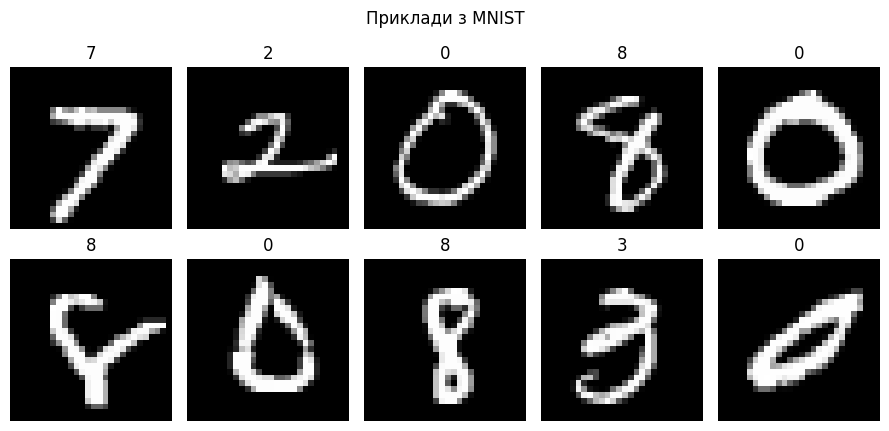

In [2]:
(x_train_all,y_train_all),(x_test_all,y_test_all)=keras.datasets.mnist.load_data()
x_train_all=x_train_all.astype('float32')[...,np.newaxis]/255.0
x_test_all=x_test_all.astype('float32')[...,np.newaxis]/255.0
print('Full train:',x_train_all.shape,'full test:',x_test_all.shape)
# Підмножина для швидкого відтворення експерименту на Colab.
# За потреби можна збільшити TRAIN_N і TEST_N до повних розмірів.
TRAIN_N=15000
TEST_N=3000
rng=np.random.default_rng(9)
train_ids=rng.permutation(len(y_train_all))[:TRAIN_N]
test_ids=rng.permutation(len(y_test_all))[:TEST_N]
x_train,y_train=x_train_all[train_ids],y_train_all[train_ids]
x_test,y_test=x_test_all[test_ids],y_test_all[test_ids]
print('Experiment train:',x_train.shape,'test:',x_test.shape)

fig,axs=plt.subplots(2,5,figsize=(9,4.5))
for i,ax in enumerate(axs.flat):
    ax.imshow(x_train[i,:,:,0],cmap='gray')
    ax.set_title(f'{y_train[i]}');ax.axis('off')
fig.suptitle('Приклади з MNIST')
plt.tight_layout();fig.savefig(OUT/'cnn_01_mnist_examples.png',dpi=170,bbox_inches='tight');plt.show()

### 2. Архітектура CNN та завантаження навченої моделі

Згорткові шари (`Conv2D`) навчаються виділяти локальні ознаки зображень; `MaxPooling2D` зменшує просторову розмірність, а завершальний `Dense` із `softmax` видає ймовірності десяти класів.

Якщо доступний **сумісний готовий файл Keras-моделі** (`.keras` або `.h5`), можна встановити `USE_PRETRAINED = True`, завантажити файл у середовище Colab та зазначити шлях у `PRETRAINED_PATH`. Тоді повторне навчання не потрібне. Якщо файл не використовується, ця робота створить і навчить модель самостійно.

In [3]:
USE_PRETRAINED = False
PRETRAINED_PATH = '/content/mnist_model.keras'
EPOCHS = 2
BATCH_SIZE = 128

def build_cnn():
    return keras.Sequential([
        keras.Input(shape=(28,28,1)),
        layers.Conv2D(32,3,activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(64,3,activation='relu'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dropout(0.3),
        layers.Dense(10,activation='softmax')
    ],name='mnist_cnn')

history=None
if USE_PRETRAINED:
    if not Path(PRETRAINED_PATH).is_file():
        raise FileNotFoundError(f'Не знайдено модель: {PRETRAINED_PATH}')
    model=keras.models.load_model(PRETRAINED_PATH,compile=False)
    if tuple(model.input_shape[1:])!=(28,28,1) or model.output_shape[-1]!=10:
        raise ValueError('Навчена модель повинна приймати 28x28x1 і повертати 10 класів MNIST')
    model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    print('Модель завантажена з файлу; навчання пропущено.')
else:
    model=build_cnn()
    model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.summary()

Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Навчання або використання готової моделі

Для оцінювання якості тестові дані не використовуються під час навчання. Частина навчального набору відводиться для валідації.

Epoch 1/2
100/100 ━━━━━━━━━━━━━━━━━━━━ 33s 280ms/step - accuracy: 0.7402 - loss: 0.8883 - val_accuracy: 0.9293 - val_loss: 0.2536
Epoch 2/2
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 126ms/step - accuracy: 0.9344 - loss: 0.2250 - val_accuracy: 0.9573 - val_loss: 0.1512
Навчена модель збережена: mnist_cnn_lab05.keras


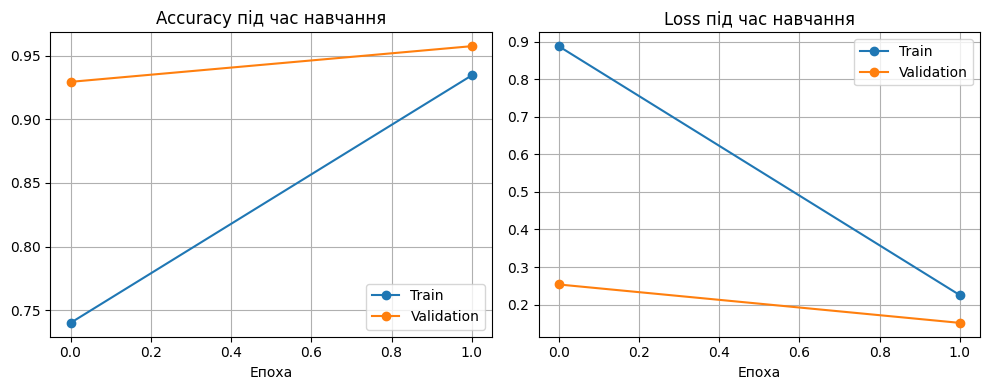

In [4]:
if not USE_PRETRAINED:
    history=model.fit(x_train,y_train,validation_split=0.15,
                      epochs=EPOCHS,batch_size=BATCH_SIZE,verbose=1)
    model.save('mnist_cnn_lab05.keras')
    print('Навчена модель збережена: mnist_cnn_lab05.keras')
else:
    print('Навчання не виконувалося, використовується готова модель.')

if history is not None:
    df=pd.DataFrame(history.history)
    df.to_csv(OUT/'cnn_history.csv',index=False,encoding='utf-8-sig')
    fig,axs=plt.subplots(1,2,figsize=(10,4))
    axs[0].plot(df['accuracy'],marker='o',label='Train');axs[0].plot(df['val_accuracy'],marker='o',label='Validation')
    axs[0].set_title('Accuracy під час навчання');axs[0].set_xlabel('Епоха');axs[0].legend();axs[0].grid(True)
    axs[1].plot(df['loss'],marker='o',label='Train');axs[1].plot(df['val_loss'],marker='o',label='Validation')
    axs[1].set_title('Loss під час навчання');axs[1].set_xlabel('Епоха');axs[1].legend();axs[1].grid(True)
    plt.tight_layout();fig.savefig(OUT/'cnn_02_learning_curves.png',dpi=170,bbox_inches='tight');plt.show()

### 4. Перевірка CNN на тестових зображеннях

Далі будуємо матрицю помилок і аналізуємо фактичні та передбачені цифри. Тестова точність обчислюється лише після завершення навчання чи завантаження готової моделі.

Test loss: 0.1331; test accuracy: 0.9603
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       276
           1       0.98      1.00      0.99       336
           2       0.98      0.92      0.95       303
           3       0.98      0.97      0.97       286
           4       0.96      0.98      0.97       284
           5       0.95      0.99      0.97       271
           6       0.97      0.96      0.97       305
           7       0.93      0.96      0.94       313
           8       0.97      0.90      0.93       309
           9       0.94      0.96      0.95       317

    accuracy                           0.96      3000
   macro avg       0.96      0.96      0.96      3000
weighted avg       0.96      0.96      0.96      3000



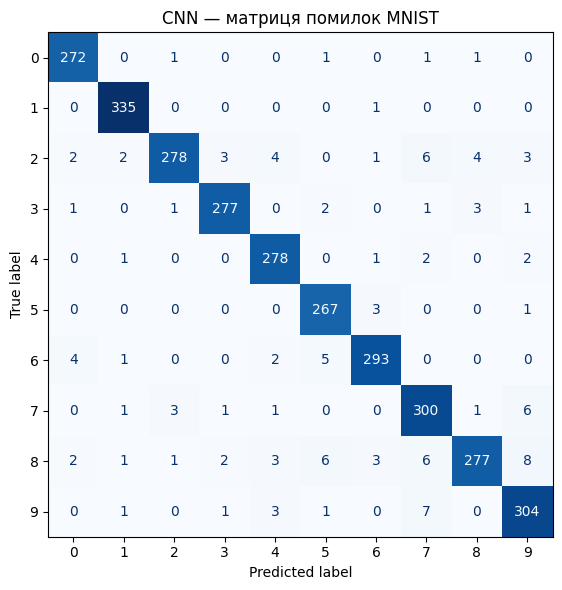

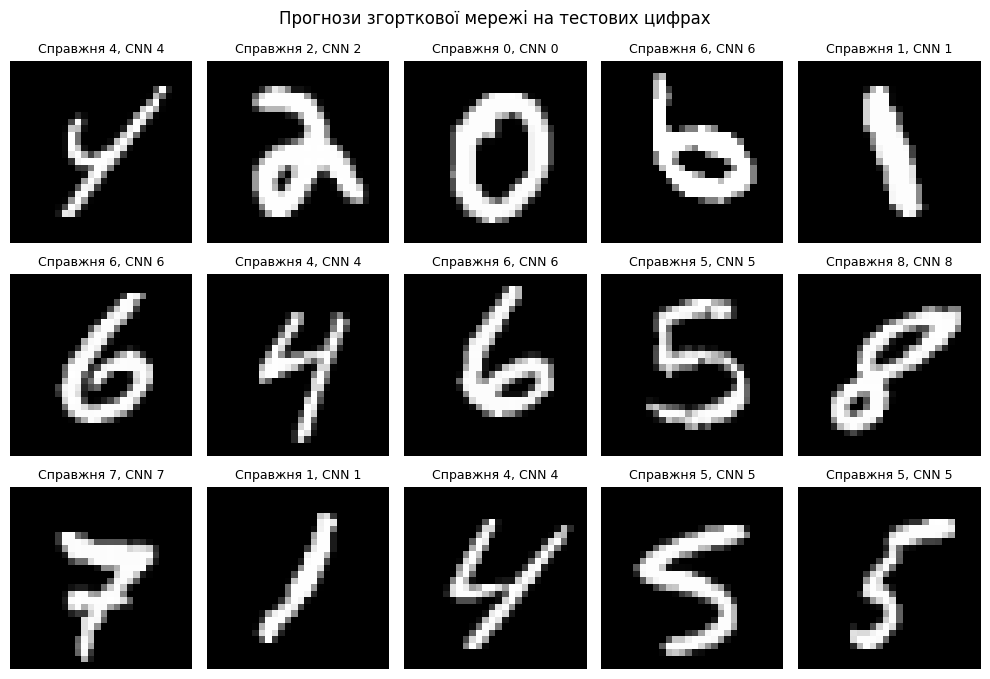

In [5]:
loss,acc=model.evaluate(x_test,y_test,verbose=0)
probs=model.predict(x_test,verbose=0)
y_pred=np.argmax(probs,axis=1)
print(f'Test loss: {loss:.4f}; test accuracy: {acc:.4f}')
print(classification_report(y_test,y_pred,zero_division=0))
pd.DataFrame([{'test_samples':len(y_test),'loss':loss,'accuracy':acc,'pretrained':USE_PRETRAINED}]).to_csv(
    OUT/'cnn_test_metrics.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,labels=np.arange(10),ax=ax,cmap='Blues',colorbar=False)
ax.set_title('CNN — матриця помилок MNIST')
plt.tight_layout();fig.savefig(OUT/'cnn_03_confusion.png',dpi=170,bbox_inches='tight');plt.show()

fig,axs=plt.subplots(3,5,figsize=(10,7))
for i,ax in enumerate(axs.flat):
    ax.imshow(x_test[i,:,:,0],cmap='gray')
    ok=y_test[i]==y_pred[i]
    ax.set_title(f'Справжня {y_test[i]}, CNN {y_pred[i]}',fontsize=9,color='black' if ok else 'red')
    ax.axis('off')
fig.suptitle('Прогнози згорткової мережі на тестових цифрах')
plt.tight_layout();fig.savefig(OUT/'cnn_04_predictions.png',dpi=170,bbox_inches='tight');plt.show()

## ВИСНОВОК

Досліджено CNN з архітектурою `Conv2D → MaxPooling2D → Conv2D → MaxPooling2D → Flatten → Dense` для класифікації рукописних цифр MNIST. Якість оцінюється на незалежній тестовій вибірці за точністю, звітом класифікації й матрицею помилок. На відміну від MLP із завдання 1, згорткова мережа працює із двовимірною структурою зображення та локальними просторовими ознаками. Пряме числове порівняння точності двох завдань некоректне без спільного набору даних: у завданні 1 — 4×4 і два класи, у завданні 2 — 28×28 і десять класів.